# 08 · Advertised salary

What did IT job ads say they pay, and did it change?

**Method.** Salary text comes in many formats ("8 Tr - 15 Tr VND", "$1,500 - $2,500", "2.0E7 (VND per MONTH)", "Cạnh tranh") and `taxonomy.parse_salary` turns it into a monthly VND range: USD at a fixed 25,000, yearly figures divided by twelve, hourly figures dropped. A posting's figure is the **midpoint of its stated range**. These are **nominal advertised figures**, not market pay: most postings carry no figure (or only "negotiable"), and who publishes a range changes by year and board. Years with fewer than 300 salaries are not shown.

In [1]:
import matplotlib.pyplot as plt

from vnjobs.analysis import core as a
from vnjobs.analysis import salary as m

a.apply_style()
con = a.connect()
df = a.load_features(con)

## 1. How many postings carry a salary

Share with a usable figure and share that only say "negotiable", "competitive" or "not disclosed".

In [2]:
coverage = m.coverage_by_year(df)
a.save_table(coverage, "08-salary-coverage")
coverage

,year,postings,pct_with_figure,pct_negotiable
0,2020,6643,28.2,12.0
1,2021,12214,52.9,45.0
2,2022,9547,45.5,50.4
3,2023,25503,13.5,15.1
4,2024,31141,6.7,8.2
5,2025,34478,8.2,7.9
6,2026,36477,7.7,11.5


## 2. The advertised range over time

Quartiles of the monthly midpoint, in millions of VND, per year with enough salaries. Left, every source; right, CareerBuilder alone (the one large source with salaries across the years).

In [3]:
overall = m.quantiles_by_year(df)
careerbuilder = m.quantiles_by_year(df, "careerbuilder_vn")
a.save_table(overall, "08-salary-quartiles-all")
a.save_table(careerbuilder, "08-salary-quartiles-careerbuilder")
overall.merge(careerbuilder, on="year", how="outer", suffixes=("_all", "_careerbuilder"))

,year,postings_all,p25_all,median_all,p75_all,postings_careerbuilder,p25_careerbuilder,median_careerbuilder,p75_careerbuilder
0,2020,1872,8.5,12.0,19.0,988,12.5,17.5,25.0
1,2021,6460,11.5,17.5,25.0,6449,11.5,17.5,25.0
2,2022,4345,11.5,16.0,25.0,4345,11.5,16.0,25.0
3,2023,3445,11.0,15.0,22.5,3008,11.5,15.5,23.1
4,2024,2097,12.0,16.5,22.5,1795,12.5,16.5,22.5
5,2025,2819,12.5,16.0,22.5,1831,12.5,15.0,20.0
6,2026,2812,15.0,20.0,26.0,526,15.0,20.0,25.9


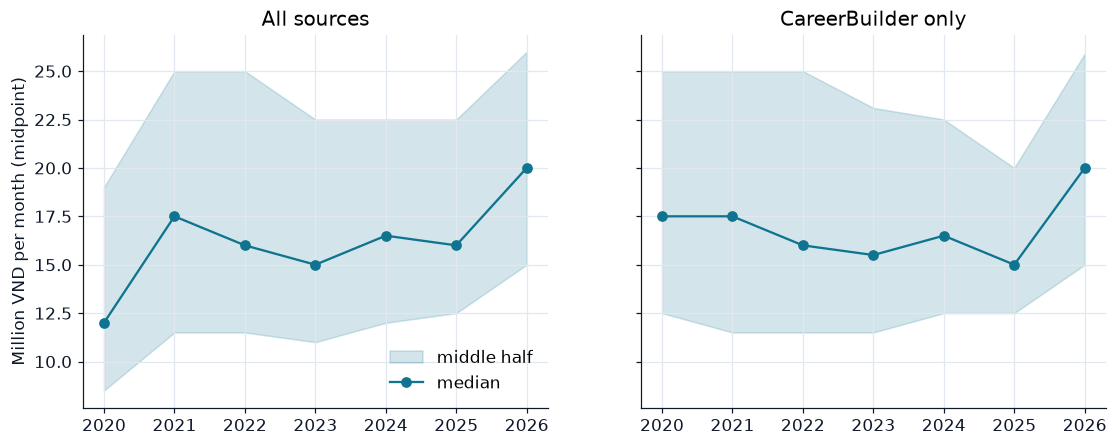

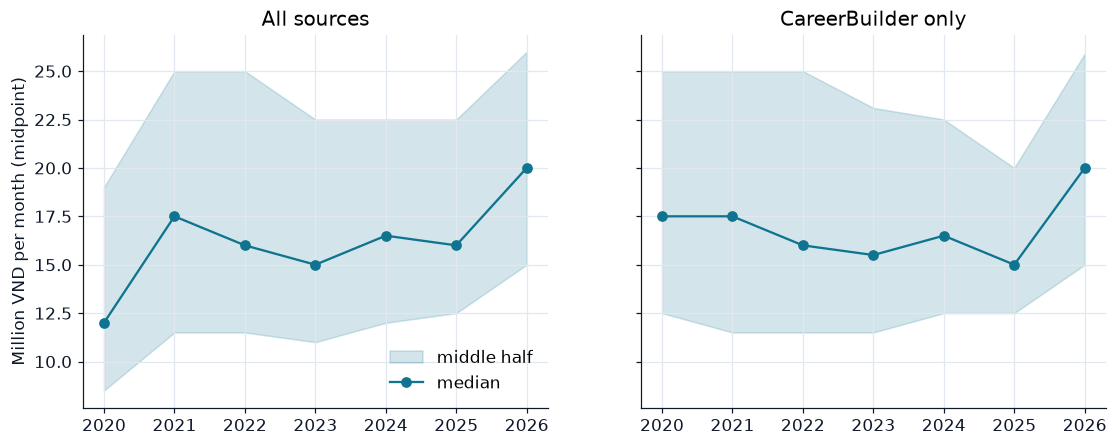

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, (label, table) in zip(
    axes, (("All sources", overall), ("CareerBuilder only", careerbuilder)), strict=True
):
    ax.fill_between(
        table.year, table.p25, table.p75, color=a.PALETTE["data"], alpha=0.18, label="middle half"
    )
    ax.plot(table.year, table["median"], marker="o", color=a.PALETTE["data"], label="median")
    ax.set_title(label)
axes[0].set_ylabel("Million VND per month (midpoint)")
axes[0].legend()
a.save_chart(fig, "08-salary-quartiles")
fig

In [5]:
checks = m.source_check(df)
a.save_table(checks, "08-salary-by-source-year")
checks.pivot(index="year", columns="source", values="median")

source,CareerBuilder,CareerViet,Indeed,Jora
year,,,,
2020,17.5,NaN,8.5,NaN
2021,17.5,NaN,NaN,NaN
2022,16.0,NaN,NaN,NaN
2023,15.5,NaN,12.5,NaN
2024,16.5,NaN,NaN,NaN
2025,15.0,NaN,NaN,18.0
2026,20.0,20.0,NaN,NaN


## 3. By role and level

Median midpoint per role (2021–22 against 2025–26), then per level for 2025–26 (levels read only from 2025). Groups with fewer than 150 salaries are left out.

In [6]:
role_early = m.median_by_group(df, "role", (2021, 2022))
role_late = m.median_by_group(df, "role", (2025, 2026))
a.save_table(role_early, "08-median-by-role-2021-2022")
a.save_table(role_late, "08-median-by-role-2025-2026")
role_early.merge(role_late, on="group", how="outer", suffixes=("_2021_22", "_2025_26")).sort_values(
    "median_2025_26", ascending=False
)

,group,postings_2021_22,median_2021_22,postings_2025_26,median_2025_26
0,backend,1437,23.8,218.0,27.5
1,data,529,18.5,313.0,20.0
2,devops_cloud,373,22.5,250.0,20.0
8,other,349,15.0,213.0,20.0
10,software_other,1304,17.5,714.0,20.0
9,qa_test,1302,15.0,876.0,17.5
6,it_support_infra,1797,12.0,859.0,15.0
11,technical_non_software,1861,12.0,1550.0,15.0
3,erp_consulting,183,22.5,NaN,NaN
4,frontend,531,25.0,NaN,NaN


In [7]:
by_level = m.median_by_group(df[df.level != "unknown"], "level", (2025, 2026))
a.save_table(by_level, "08-median-by-level-2025-2026")
by_level

,group,postings,median
4,senior,432,33.0
2,lead,294,25.0
3,mid,1645,20.0
1,junior,1601,15.0
0,intern,174,5.0


## Findings

1. **Salary data thins out sharply.** Postings with a usable figure: 28 % (2020), 53 % (2021), 46 % (2022), then 13.5 % (2023), 6.7 % (2024), 8.2 % (2025), 7.7 % (2026). In 2021–22 another 45–50 % say only "negotiable" or "competitive"; later it is 8–15 %. Anything after 2022 rests on a small, selective minority.
2. **The advertised median is flat at about 15–17.5 million VND a month, 2021 to 2025.** All sources: 17.5 (2021), 16.0, 15.0, 16.5, 16.0 (2025). CareerBuilder alone: 17.5, 16.0, 15.5, 16.5, 15.0. The middle half of ads spans roughly 11.5 to 25 million in 2021–22 and 12.5 to 22.5 million by 2025. These are nominal figures with no inflation adjustment, so a flat line is a real-terms fall, which this notebook does not quantify.
3. **2026 looks higher (20 million) but should not be over-read.** CareerBuilder's 2026 figure is 20.0 million on only 526 salaries, and the all-source 2026 median includes CareerViet (2,120 salaries, median 20 million), a source that did not exist in earlier years.
4. **By role, within very different windows.** 2021–22: full-stack 28.5, frontend 25.0, backend 23.8, mobile 23.2, DevOps and ERP 22.5, data 18.5, general software 17.5, QA 15.0, IT support and technicians 12.0 million. 2025–26: backend 27.5, data 20.0, DevOps 20.0, general software 20.0, QA 17.5, IT support and technicians 15.0 million. AI / ML, frontend and full-stack have too few salaries in 2025–26 to report. The source and role mix differ between the two windows, so treat the gaps as indicative.
5. **By level (2025–26):** intern 5, junior 15, mid 20, lead 25 and senior 33 million. Lead sits below senior, probably because "lead" labels include team leaders and supervisors in non-software jobs.

**What this notebook cannot say:** what IT people are actually paid, or pay by role for AI work. It shows what a minority of ads chose to publish.
